# Supplementary figures — fine-tuning notebook

Each figure below is re-drawn from the **already-saved** results in `results/analyses/` (CSVs + `exact_summary.json`) and hardware JSON. Nothing is recomputed, so you can freely tweak colors, labels, legends and sizes and re-run a single cell.

**Run the Setup cell first**, then any figure cell. Each cell saves `pdf/png/svg` into `results/analyses/figures/` and shows the figure inline. (Mirrors `analysis_tools/make_si_figures.py`.)


## Setup


In [2]:
# === Setup: run this first ===
import os, sys, json, itertools, glob
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
try:
    from sklearn.metrics import roc_curve, roc_auc_score
except Exception:
    roc_curve = roc_auc_score = None  # only needed for Fig S5

# Find the python/ dir that contains results/analyses/exact_summary.json
BASE = os.path.abspath("")
while BASE != os.path.dirname(BASE) and not os.path.isfile(os.path.join(BASE, "results", "analyses", "exact_summary.json")):
    BASE = os.path.dirname(BASE)

assert os.path.isfile(os.path.join(BASE, "results", "analyses", "exact_summary.json")), \
    "Could not find exact_summary.json above the notebook. Set BASE manually to .../QuantumXCT/python"

os.chdir(BASE)
sys.path.insert(0, BASE)
print("working dir:", BASE)

R = "results/analyses"
F = os.path.join(R, "figures")
os.makedirs(F, exist_ok=True)

def save(fig, name):
    """Save pdf/png/svg and keep the figure for inline display (does not close it)."""
    for ext in ("pdf", "png", "svg"):
        fig.savefig(f"{F}/{name}.{ext}", bbox_inches="tight")
    print("saved", name, "->", F)

BLUE, ORANGE, AQUA, YELLOW, VIOLET, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7", "#8a8984"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "legend.frameon": False,
                     "savefig.bbox": "tight", "savefig.dpi": 300})

summ = json.load(open(f"{R}/exact_summary.json"))
print("datasets:", list(summ.keys()))

working dir: C:\Users\selim\Escritorio\claude_coworks\quantumXCT_reviews\QuantumXCT_code\QuantumXCT\python
datasets: ['synthetic', 'ovarian']


## Fig S1: exact vs sampled contribution (manuscript Table 2, L2 multi-epoch)


saved figS3_exact_vs_sampled -> results/analyses\figures


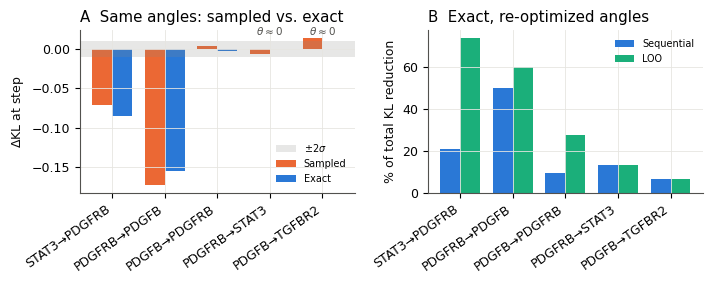

In [6]:
t2 = pd.read_csv(f"{R}/table2_exact_audit_L2.csv")
old = {"STAT3 -> PDGFRB": -0.071, "PDGFRB -> PDGFB": -0.173, "PDGFB -> PDGFRB": 0.004,
       "PDGFRB -> STAT3": -0.007, "PDGFB -> TGFBR2": 0.014}
me = t2[(t2.algorithm == "Multi-epoch") & (t2.angles == "manuscript angles")]

fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.9))
x = np.arange(len(me))
w = 0.38

# --- Panel A: Sampled vs Exact ---
ax[0].bar(x - w / 2, [old[g] for g in me.gate], w, color=ORANGE, label="Sampled")
ax[0].bar(x + w / 2, me.dKL_step, w, color=BLUE, label="Exact")

sd = me.shot_sd_final_kl.iloc[0]
ax[0].axhspan(-2 * sd, 2 * sd, color=GRAY, alpha=0.2, lw=0, label=r"$\pm 2\sigma$")

ax[0].set_xticks(x)
ax[0].set_xticklabels([g.replace(" -> ", "→") for g in me.gate], rotation=35, ha="right")
ax[0].set_ylabel(r"$\Delta$KL at step")
ax[0].set_title("A  Same angles: sampled vs. exact", loc="left")
ax[0].legend(fontsize=7, loc="lower right", frameon=False)

for i, th in enumerate(me.theta_rad):
    if th < 1e-3:
        ax[0].annotate(r"$\theta\approx 0$", (i, 0.018), ha="center", fontsize=7.5, color="#52514e")

# --- Panel B: Exact Re-optimized (Sequential vs LOO) ---
ro = t2[(t2.algorithm == "Multi-epoch") & (t2.angles == "exact re-optimized")]
ax[1].bar(x - w / 2, ro.pct_of_total_reduction_step, w, color=BLUE, label="Sequential")
ax[1].bar(x + w / 2, ro.pct_LOO_of_total_reduction, w, color=AQUA, label="LOO")

ax[1].set_xticks(x)
ax[1].set_xticklabels([g.replace(" -> ", "→") for g in ro.gate], rotation=35, ha="right")
ax[1].set_ylabel("% of total KL reduction")
ax[1].set_title("B  Exact, re-optimized angles", loc="left")
ax[1].legend(fontsize=7, loc="upper right", frameon=False)

fig.tight_layout()
save(fig, "figS3_exact_vs_sampled")

## Fig S2 — random-topology null  *(improved formatting)*


saved figS2_random_null -> results/analyses\figures
copied PDF -> C:\Users\selim\Escritorio\claude_coworks\quantumXCT_reviews\QuantumXCT_KL_paper\revision


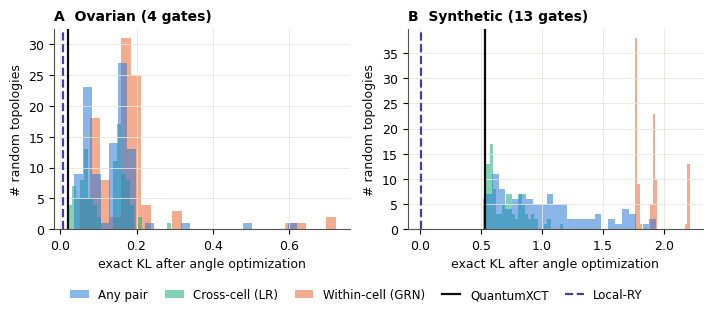

In [4]:
# Fig S2: random-topology null  (improved: legend below both panels, uppercase A/B,
# QuantumXCT line at the exact-reoptimized loss to match Table S2 / the x-axis)
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.1))
for ax, name, panel in zip(axs, ["ovarian", "synthetic"], ["A", "B"]):
    m = summ[name]; bins = 25
    for tag, col in [("intra", ORANGE), ("inter", AQUA), ("all", BLUE)]:
        v = pd.read_csv(f"{R}/{name}_random_null_{tag}.csv").iloc[:, 0].values
        ax.hist(v, bins=bins, color=col, alpha=0.55)
    ax.axvline(m["final_kl_exact_reoptimized"], color="#0b0b0b", lw=1.6)   # QuantumXCT
    ax.axvline(m["local_RY_only_kl"], color=VIOLET, lw=1.6, ls="--")        # local-RY
    ax.set_xlabel("exact KL after angle optimization"); ax.set_ylabel("# random topologies")
    #ax.set_title(f"{panel}  {name} ({m['n_gates']} gates)", loc="left", fontsize=10, fontweight="bold")
    ax.set_title(f"{panel}  {name.capitalize()} ({m['n_gates']} gates)", loc="left", fontsize=10, fontweight="bold")
    
handles = [Patch(fc=BLUE, alpha=0.55, label="Any pair"),
           Patch(fc=AQUA, alpha=0.55, label="Cross-cell (LR)"),
           Patch(fc=ORANGE, alpha=0.55, label="Within-cell (GRN)"),
           Line2D([0], [0], color="#0b0b0b", lw=1.6, label="QuantumXCT"),
           Line2D([0], [0], color=VIOLET, lw=1.6, ls="--", label="Local-RY")]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=8.5, frameon=False,
           bbox_to_anchor=(0.5, -0.02), columnspacing=1.4, handlelength=1.6)
fig.tight_layout(rect=[0, 0.07, 1, 1]); save(fig, "figS1_random_null")

# refresh the copy the paper includes:
import shutil
_rev = os.path.normpath(os.path.join(BASE, "..", "..", "..", "QuantumXCT_KL_paper", "revision"))
if os.path.isdir(_rev):
    shutil.copy(f"{F}/figS1_random_null.pdf", f"{_rev}/figS1_random_null.pdf"); print("copied PDF ->", _rev)


## Fig S3 (budget sweep) removed

> The effective-dof budget-matched benchmark (budget_sweep_v2 / budget_matched_v2) was
> dropped from the revision, so this figure is no longer generated. The capacity-reference
> comparison now lives in the D=1/D=2 master table (compile_budget_table.py).
> 


## Fig S4: bootstrap edge frequencies


saved figS4_bootstrap_edges -> results/analyses\figures


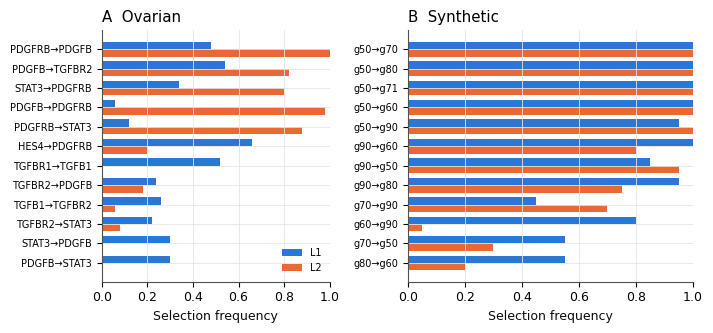

In [7]:
def edge_freq(fn):
    b = pd.read_csv(fn); out = {}
    for norm, sub in b.groupby("norm"):
        cnt = {}
        for e in sub.edges.fillna(""):
            for x in set(filter(None, e.split(";"))):
                cnt[x] = cnt.get(x, 0) + 1
        out[norm] = {k: v / len(sub) for k, v in cnt.items()}
    return out, b

freq_tables = {}
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.4), gridspec_kw={"width_ratios": [1, 1.25]})

for ax, (name, fn) in zip(axs, [("ovarian", f"{R}/ovarian_boot.csv"), ("synthetic", f"{R}/sim_boot.csv")]):
    if not os.path.exists(fn):
        continue
    fr, b = edge_freq(fn)
    edges = sorted(set(fr.get("l1", {})) | set(fr.get("l2", {})),
                   key=lambda e: -(fr.get("l1", {}).get(e, 0) + fr.get("l2", {}).get(e, 0)))[:12]
    y = np.arange(len(edges)); h = 0.38
    
    # Legend labels simplified to L1 and L2
    ax.barh(y - h / 2, [fr["l1"].get(e, 0) for e in edges], h, color=BLUE, label="L1")
    ax.barh(y + h / 2, [fr["l2"].get(e, 0) for e in edges], h, color=ORANGE, label="L2")
    
    ax.set_yticks(y)
    ax.set_yticklabels([e.replace("->", "→").replace("Gene_", "g") for e in edges], fontsize=7)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    
    # Cleaned x-axis label
    ax.set_xlabel("Selection frequency")
    
    # Upper case subplot tags (A/B) and capitalized dataset names
    panel_letter = "A" if name == "ovarian" else "B"
    ax.set_title(f"{panel_letter}  {name.capitalize()}", loc="left")
    
    freq_tables[name] = pd.DataFrame({"edge": edges, 
                                      "L1": [fr["l1"].get(e, 0) for e in edges],
                                      "L2": [fr["l2"].get(e, 0) for e in edges]})
    freq_tables[name].to_csv(f"{R}/{name}_bootstrap_edge_frequency.csv", index=False)

axs[0].legend(fontsize=7, loc="lower right")
fig.tight_layout()
save(fig, "figS4_bootstrap_edges")

## Fig S5: single-edge ROC on synthetic


saved figS5_synthetic_roc -> results/analyses\figures


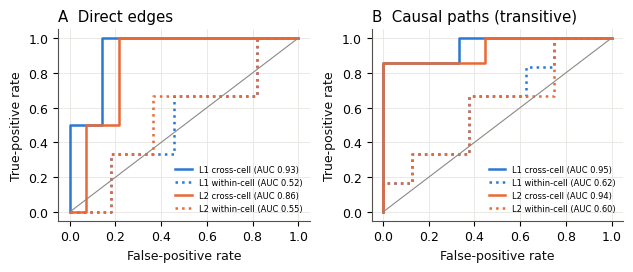

In [15]:
se = pd.read_csv(f"{R}/synthetic_single_edge_scores.csv")
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.8))
for ax, lab in zip(axs, ["direct", "closure"]):
    for norm, col in [("l1", BLUE), ("l2", ORANGE)]:
        for scope, ls in [("inter", "-"), ("intra", ":")]:
            s = se[(se.norm == norm) & (se.scope == scope)]
            fpr, tpr, _ = roc_curve(s[lab], s.score)
            ax.plot(fpr, tpr, color=col, ls=ls, lw=1.8,
                    label=f"{norm.upper()} {'cross-cell' if scope=='inter' else 'within-cell'} (AUC {roc_auc_score(s[lab], s.score):.2f})")
    ax.plot([0, 1], [0, 1], color=GRAY, lw=0.8)
    ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
    ax.set_title(f"{'A' if lab=='direct' else 'B'}  {'Direct edges' if lab=='direct' else 'Causal paths (transitive)'}", loc="left")
    ax.legend(fontsize=6, loc="lower right")
fig.tight_layout(); save(fig, "figS5_synthetic_roc")



## Fig S6: scaling


saved figS6_scaling -> results/analyses/figures


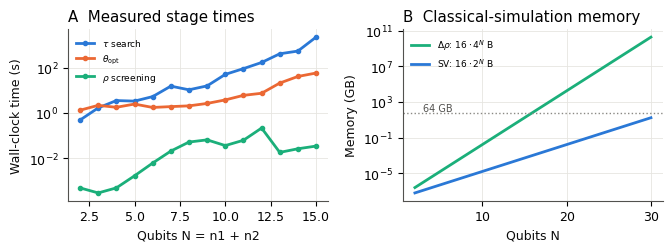

In [7]:
import os, glob as _glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# --- palette + style (from make_si_figures.py) ---
BLUE, ORANGE, AQUA, YELLOW, VIOLET, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7", "#8a8984"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "legend.frameon": False,
                     "savefig.bbox": "tight", "savefig.dpi": 300})

# --- output dir + save helper (writes pdf/png/svg) ---
F = "results/analyses/figures"; os.makedirs(F, exist_ok=True)
# --- Fig S6: scaling ---
# Prefer the SAMPLED runtime curve (SI Section S10: 2 epochs, depth 4, 1000 shots).
_scal_cands = ["results/scaling/scaling_results_sampled.csv", "results/scaling/scaling_results.csv"]
_scal = next((p for p in _scal_cands if os.path.exists(p)),
             next(iter(sorted(_glob.glob("results/scaling/scaling_results*.csv"))), _scal_cands[-1]))
sc = pd.read_csv(_scal)

fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.6))
axs[0].plot(sc.total_qubits, sc.t_search_s,   color=BLUE,   marker="o", ms=3, lw=2, label=r"$\tau$ search")
axs[0].plot(sc.total_qubits, sc.t_optimize_s, color=ORANGE, marker="o", ms=3, lw=2, label=r"$\theta_{\mathrm{opt}}$")
axs[0].plot(sc.total_qubits, sc.t_screen_s,   color=AQUA,   marker="o", ms=3, lw=2, label=r"$\rho$ screening")
axs[0].set_yscale("log"); axs[0].set_xlabel("Qubits N = n1 + n2"); axs[0].set_ylabel("Wall-clock time (s)")
axs[0].legend(fontsize=6.5); axs[0].set_title("A  Measured stage times", loc="left")

N = np.arange(2, 31)
axs[1].plot(N, 16 * 4.0 ** N / 1e9, color=AQUA, lw=2, label=r"$\Delta\rho$: $16\cdot4^N$ B")
axs[1].plot(N, 16 * 2.0 ** N / 1e9, color=BLUE, lw=2, label=r"SV: $16\cdot2^N$ B")
axs[1].axhline(64, color=GRAY, ls=":", lw=1); axs[1].text(3, 90, "64 GB", fontsize=7, color="#52514e")
axs[1].set_yscale("log"); axs[1].set_xlabel("Qubits N"); axs[1].set_ylabel("Memory (GB)")
axs[1].legend(fontsize=6.5); axs[1].set_title("B  Classical-simulation memory", loc="left")

fig.tight_layout(); save(fig, "figS6_scaling"); plt.show()